In [1]:
import pandas as pd
from tqdm import tqdm
import itertools
import os
import jieba
from gensim.models import Word2Vec
import numpy as np
from gensim import matutils
from nltk.tokenize import word_tokenize
import gensim.downloader as api
import csv

# training chinese model

In [4]:
folder_path = "/Users/shemingrong/Chinese_author_names/Version3"  
file_name = "model_cn" 
file_path = os.path.join(folder_path, file_name)
if os.path.exists(file_path):
    model_cn = Word2Vec.load(file_path)
else:
    # Select the title, abstract and keywords of each paper, and form a text in the form of string splicing in order, which is used to represent this paper.
    paperinfos_cn = []
    with open('../DisambiguationData/CNKI_dataset_updated_withValidNames_withPID_FullChinese.csv', 'r') as f:
        for i, row in tqdm(enumerate(csv.reader(f))):
            if i != 0:
                if row[7] == '无':
                    sen = row[1] + '。' + row[8]
                elif row[8] == '无':
                    sen = row[1] + '。' + row[7]
                else:
                    sen = row[1] + '。' + row[7] + '。' + row[8]

                wordCut = list(jieba.cut(sen))
                paperinfos_cn.append(wordCut)
    model_cn = Word2Vec(paperinfos_cn, sg=0, vector_size=200, window=5, min_count=1, negative=3, sample=0.001, hs=1,
                         workers=4)
    model_cn.save('model_cn')

In [7]:
def cosine_similarity_cn(vector1, vector2):
    return np.dot(vector1, vector2) / (np.linalg.norm(vector1) * np.linalg.norm(vector2))

def calculate_similarity_cn(text1, text2):
    # 分词并获取有效词的向量表示
    vectors1 = [model_cn.wv[word] for word in jieba.cut(text1) if word in model_cn.wv]
    vectors2 = [model_cn.wv[word] for word in jieba.cut(text2) if word in model_cn.wv]
    
    # 计算文本向量的平均值
    if vectors1 and vectors2:
        vector1 = matutils.unitvec(np.mean(vectors1, axis=0))
        vector2 = matutils.unitvec(np.mean(vectors2, axis=0))
        similarity = cosine_similarity_cn(vector1, vector2)
    else:
        similarity = 0

    return similarity

# training English model

In [ ]:
folder_path = "/Users/shemingrong/Chinese_author_names/Version3"  
file_name = "model_en" 
file_path = os.path.join(folder_path, file_name)
if os.path.exists(file_path) is False:
    model_en = Word2Vec.load(file_path)
else:
    Paper_Translation = pd.read_csv('../DisambiguationData/Paper_Translation.csv')
    title_cn_en = dict(zip(Paper_Translation['Title'], Paper_Translation['Title_English']))
    abstract_cn_en = dict(zip(Paper_Translation['Abstract'], Paper_Translation['Abstract_English']))
    keywords_cn_en = dict(zip(Paper_Translation['Keywords'], Paper_Translation['Keywords_English']))
    # Select the title, abstract and keywords of each paper, and form a text in the form of string splicing in order, which is used to represent this paper.
    paperinfos_en = []
    with open('../DisambiguationData/CNKI_dataset_updated_withValidNames_withPID_FullChinese.csv', 'r') as f:
        for i, row in tqdm(enumerate(csv.reader(f))):
            if i != 0:
                title_en = title_cn_en[row[1]]
                abstract_en = abstract_cn_en[row[8]]
                keyword_en = keywords_cn_en[row[7]]
                if row[7] == '无':
                    sen = title_en + '。' + abstract_en
                elif row[8] == '无':
                    sen = title_en + '。' + keyword_en
                else:
                    sen = title_en + '。' + keyword_en + '。' + abstract_en
                wordCut = word_tokenize(sen.lower())
                paperinfos_en.append(wordCut)

    model_en = Word2Vec(paperinfos_en, sg=0, vector_size=200, window=5, min_count=1, negative=3, sample=0.001, hs=1,
                             workers=4)
    model_en.save('model_en')

In [10]:
def cosine_similarity_en(vector1, vector2):
    return np.dot(vector1, vector2) / (np.linalg.norm(vector1) * np.linalg.norm(vector2))

def calculate_similarity_en(text1, text2):
    # 英文分词并获取有效词的向量表示
    vectors1 = [model_en.wv[word] for word in word_tokenize(text1.lower()) if word in model_en.wv]
    vectors2 = [model_en.wv[word] for word in word_tokenize(text2.lower()) if word in model_en.wv]
    
    # 计算文本向量的平均值
    if vectors1 and vectors2:
        vector1 = matutils.unitvec(np.mean(vectors1, axis=0))
        vector2 = matutils.unitvec(np.mean(vectors2, axis=0))
        similarity = cosine_similarity_en(vector1, vector2)
    else:
        similarity = 0

    return similarity

# calculate similarity between abstracts

In [12]:
name_cn = pd.read_csv('../DisambiguationData/Authorship_ValidChinese.csv')
name_en = pd.read_csv('../DisambiguationData/Authorship_English.csv')
cn_pid_ab = dict(zip(name_cn['paper id'],name_cn['abstract']))
en_pid_ab = dict(zip(name_en['paper id'],name_en['abstract']))

In [15]:
def calculate_similarities(name_en):
    result_df = name_en.groupby('author_name')['paper id'].apply(list).reset_index()
    name_pids = dict(zip(result_df['author_name'], result_df['paper id']))
    with open("../DisambiguationData/AbstractSimilarity.csv", 'w', encoding='utf-8') as fw:
        csv_write = csv.writer(fw)
        csv_head = ["author_name", "paper_index1", 'paper_index2', 'similarity_cn', 'similarity_en']
        csv_write.writerow(csv_head)

        for name in tqdm(name_pids):
            pids = name_pids[name]
            if len(pids) > 1:
                combinations = list(itertools.combinations(pids, 2))
                for pair in combinations:
                    pid1 = pair[0]
                    pid2 = pair[1]
                    if en_pid_ab[pid1] !=  'none' and en_pid_ab[pid2] != 'none':
                        similarity_cn = calculate_similarity_cn(cn_pid_ab[pid1], cn_pid_ab[pid2])
                        similarity_en = calculate_similarity_en(en_pid_ab[pid1], en_pid_ab[pid2])
                    else:
                        similarity_cn = 0
                        similarity_en = 0
                    csv_write.writerow([name, pid1, pid2, similarity_cn, similarity_en])

In [16]:
calculate_similarities(name_en)

100%|█████████████████████████████████████| 68620/68620 [1:20:54<00:00, 14.14it/s]


# calculate correlation

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel
from scipy import stats
import seaborn as sns

def plot_corre(data1, data2): 
    # 计算皮尔逊相关系数
    pearson_correlation, p_value = stats.pearsonr(data1, data2)
    print(f"pearson_correlation:{pearson_correlation}, P-value: {p_value}")

    plt.figure(figsize=(14, 6))

    # 第一个图：散点图
    plt.subplot(1, 2, 1)  # 1行2列，第一个子图
    plt.scatter(data1, data2, s =2)
#     plt.axhline(y=min_x, color='b', linestyle='--')
#     plt.axvline(x=min_y, color='b', linestyle='--')
    plt.title("Cosine Similarities of Chinese and English Abstracts")
    plt.xlabel("Chinese Similarity")
    plt.ylabel("English Similarity")

    # 第二个图：KDE 图
    plt.subplot(1, 2, 2)  # 1行2列，第二个子图
    sns.kdeplot(data1, bw_adjust=0.2, label='Chinese')
    sns.kdeplot(data2, bw_adjust=0.2, label='English')

    # 添加标题和标签
    plt.xlabel('Similarity score')
    plt.ylabel('Density')
    plt.title('Probability Density Function')
    plt.legend()

    # 显示图表
    plt.tight_layout()
    plt.show()

In [35]:
simarility_titles = pd.read_csv("../DisambiguationData/AbstractSimilarity.csv")
# simarility_titles = simarility_titles[simarility_titles['similarity_en'] !=0]

pearson_correlation:0.894803280800208, P-value: 0.0


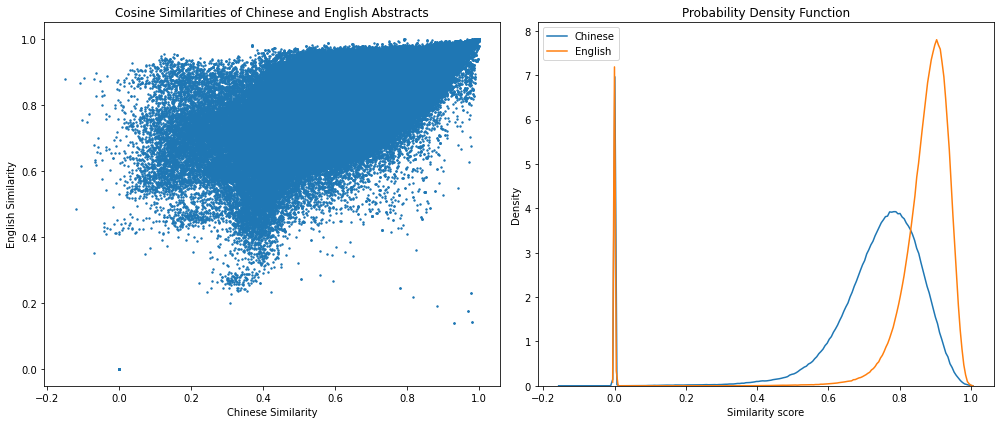

In [36]:
plot_corre(simarility_titles['similarity_cn'], simarility_titles['similarity_en'])

In [37]:
import numpy as np

# Set the parameter space
cn_thresholds = np.linspace(0.9, 1.0, num=30)  
en_thresholds = np.linspace(0.9, 1.0, num=30)


best_params = None
min_intersection_diff = float('inf')
min_diff_count = float('inf')

for cn_threshold in cn_thresholds:
    for en_threshold in en_thresholds:
        cn_above = simarility_titles['similarity_cn'] >= cn_threshold
        en_above = simarility_titles['similarity_en'] >= en_threshold
        a = simarility_titles[cn_above].index.to_list()
        b = simarility_titles[en_above].index.to_list()
        

        intersection = np.sum(cn_above & en_above)
        diff_count = np.sum(cn_above ^ en_above)
        

        if len(a) > 0 and len(b) > 0:
            intersection_diff = abs(intersection / len(a) - intersection / len(b))
        else:
            intersection_diff = float('inf')
        

        if intersection_diff < min_intersection_diff  and diff_count < min_diff_count:
            min_intersection_diff = intersection_diff
            min_diff_count = diff_count
            best_params = (cn_threshold, en_threshold)

print(f"Optimal Chinese Threshold: {best_params[0]}, Optimal English Threshold: {best_params[1]}")
print(f"Minimum Intersection Difference: {min_intersection_diff}, Minimum Difference Count: {min_diff_count}")


Optimal Chinese Threshold: 0.9206896551724139, Optimal English Threshold: 0.9620689655172414
Minimum Intersection Difference: 0.0028157651049169896, Minimum Difference Count: 42586
